In [1]:
import tensorflow as tf
from tensorflow import keras
import matplotlib.pyplot as plt
import numpy as np

print("TensorFlow version:", tf.__version__)

TensorFlow version: 2.21.0


## Step 2: Load the MNIST dataset
MNIST contains 60,000 training images and 10,000 testing images. Each image is a 28 × 28 grayscale image of a handwritten digit (0–9).

In [2]:
(x_train, y_train), (x_test, y_test) = keras.datasets.mnist.load_data()

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


## Step 3: Display dataset information

In [3]:
print("Training images:", x_train.shape)
print("Training labels:", y_train.shape)
print("Testing images:", x_test.shape)
print("Testing labels:", y_test.shape)

Training images: (60000, 28, 28)
Training labels: (60000,)
Testing images: (10000, 28, 28)
Testing labels: (10000,)


## Step 4: Normalize the image data
Convert image arrays to `float32` and divide pixel values by 255 so that they are in the range 0 to 1.

In [4]:
x_train = np.asarray(x_train, dtype=np.float32)
x_train /= 255.0

x_test = np.asarray(x_test, dtype=np.float32)
x_test /= 255.0

print("Training pixel range:", x_train.min(), "to", x_train.max())
print("Testing pixel range:", x_test.min(), "to", x_test.max())

Training pixel range: 0.0 to 1.0
Testing pixel range: 0.0 to 1.0


## Step 5: Define the Feedforward Neural Network
The network contains a Flatten layer, one hidden Dense layer with 128 neurons and ReLU activation, and an output layer with 10 neurons and softmax activation.

In [5]:
model = keras.Sequential([
    keras.layers.Flatten(input_shape=(28, 28)),
    keras.layers.Dense(128, activation='relu'),
    keras.layers.Dense(10, activation='softmax')
])

model.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/reshaping/flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 101,770 (397.54 KB)

 Trainable params: 101,770 (397.54 KB)

 Non-trainable params: 0 (0.00 B)

## Step 6: Compile the model using SGD

In [6]:
model.compile(
    optimizer=keras.optimizers.SGD(learning_rate=0.01),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

## Step 7: Train the model
Train for 10 epochs with a batch size of 32 and use 10% of the training data for validation.

In [7]:
history = model.fit(
    x_train,
    y_train,
    epochs=10,
    batch_size=32,
    validation_split=0.1
)

Epoch 1/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.8311 - loss: 0.6800 - val_accuracy: 0.9163 - val_loss: 0.3219
Epoch 2/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.9026 - loss: 0.3503 - val_accuracy: 0.9285 - val_loss: 0.2583
Epoch 3/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.9167 - loss: 0.2976 - val_accuracy: 0.9388 - val_loss: 0.2272
Epoch 4/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.9247 - loss: 0.2658 - val_accuracy: 0.9453 - val_loss: 0.2057
Epoch 5/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.9323 - loss: 0.2419 - val_accuracy: 0.9490 - val_loss: 0.1904
Epoch 6/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.9371 - loss: 0.2226 - val_accuracy: 0.9532 - val_loss: 0.1759
Epoch 7/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.9416 - loss: 0.2069 - val_accuracy: 0.9565 - val_loss: 0.1667
Epoch 8/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.9461 - loss: 0.1931 - 

## Step 8: Evaluate the model on test data

In [8]:
test_loss, test_accuracy = model.evaluate(x_test, y_test, verbose=1)

print("Test Loss:", test_loss)
print("Test Accuracy:", test_accuracy * 100, "%")

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9510 - loss: 0.1648
Test Loss: 0.16475898027420044
Test Accuracy: 95.09999752044678 %


## Step 9: Plot the training loss

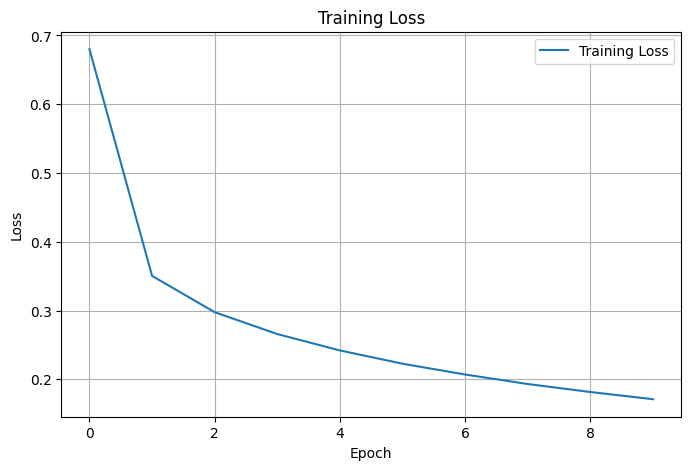

In [9]:
plt.figure(figsize=(8, 5))
plt.plot(history.history['loss'], label='Training Loss')
plt.title('Training Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)
plt.show()

## Step 10: Plot training and validation accuracy
The practical aim also asks for an accuracy plot, so this additional plot shows training and validation accuracy across epochs.

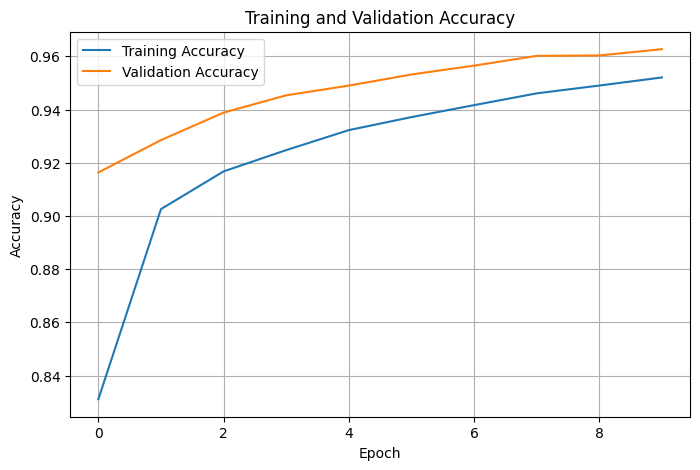

In [10]:
plt.figure(figsize=(8, 5))
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title('Training and Validation Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)
plt.show()

1. Aim
To implement a Feedforward Neural Network (FNN) using Keras and TensorFlow, train it on the MNIST handwritten digit dataset using the Stochastic Gradient Descent (SGD) optimizer, evaluate its performance, and plot training loss and accuracy.
2. Theory
Feedforward Neural Network (FNN)

A Feedforward Neural Network is a type of Artificial Neural Network (ANN) in which information flows in one direction, from the input layer through hidden layers to the output layer. There are no loops or feedback connections in the network.

It is commonly used for classification and prediction tasks.

Layers of a Feedforward Neural Network:
1. Input Layer: Receives input data. In this practical, each image has 28 × 28 pixels.
2. Hidden Layer: Processes input data using weights, biases, and activation functions. We use 128 neurons with ReLU activation.
3. Output Layer: Produces the final prediction. It contains 10 neurons representing digits from 0 to 9.
3. MNIST Dataset
MNIST is a popular dataset used for handwritten digit recognition.
- Total images: 70,000
- Training images: 60,000
- Testing images: 10,000
- Image size: 28 × 28 pixels
- Classes: 10 (digits 0–9)
- Image type: Grayscale
4. Activation Functions
ReLU (Rectified Linear Unit)

ReLU is used in the hidden layer to introduce non-linearity.
\[
f(x)=\max(0,x)
\]

It returns zero for negative inputs and the input itself for positive values.

Softmax Activation Function

Softmax is used in the output layer to convert output values into probabilities for each class.
\[
Softmax(x_i)=\frac{e^{x_i}}{\sum_j e^{x_j}}
\]

The class with the highest probability is selected as the predicted digit.
5. Stochastic Gradient Descent (SGD)
SGD is an optimization algorithm used to update the weights and biases of a neural network to minimize the loss function.

It updates model parameters using a small batch of training examples.

The weight update equation is:
\[
W_{new}=W_{old}-\eta \frac{\partial L}{\partial W}
\]

Where:
- \(W\) = Weight
- \(\eta\) = Learning rate
- \(L\) = Loss function
- \(\frac{\partial L}{\partial W}\) = Gradient of loss with respect to weight
In this practical, the learning rate is 0.01.
6. Loss Function
Sparse Categorical Crossentropy is used as the loss function because the output contains multiple classes (0–9), and labels are represented as integer values.

It measures the difference between actual labels and predicted probabilities.
7. Data Normalization
Normalization converts pixel values from the range 0–255 into the range 0–1.
\[
X_{normalized}=\frac{X}{255}
\]

It helps the neural network train more efficiently and improves numerical stability.
8. Model Training
The model is trained using the following parameters:
- Epochs: 10
- Batch size: 32
- Validation split: 10%
- Optimizer: SGD
- Learning rate: 0.01
An epoch represents one complete pass through the training dataset.
9. Model Evaluation
After training, the model is evaluated using the testing dataset.

Two important evaluation metrics are:
- Loss: Measures prediction error.
- Accuracy: Measures the percentage of correctly classified images.
\[
Accuracy=\frac{Correct\ Predictions}{Total\ Predictions}\times100
\]

10. Visualization
Matplotlib is used to visualize:
- Training loss across epochs.
- Training accuracy across epochs.
- Validation accuracy across epochs.
These graphs help understand the learning performance of the neural network.
11. Applications
1. Handwritten digit recognition.
2. Image classification.
3. Pattern recognition.
4. Optical Character Recognition (OCR).
5. Automated document processing.
12. Result
The Feedforward Neural Network was successfully implemented using Keras and TensorFlow. The model was trained on the MNIST handwritten digit dataset using the SGD optimizer, evaluated using test data, and training loss and accuracy graphs were plotted.